### Objective and data sources

Check whether the monitoring data from PVDAQ System 2107 can be used to investigate periods of low solar generation.

- **AC meter data** — average AC power (kW) at 15-minute intervals.
- **Irradiance data** — sunlight reaching the plane of the panels (W/m²).
- **System metadata** — site details, sensor definitions and time zone.

Both data files use `measured_on` for timestamps.

### Load and inspect the monitoring data

In [2]:
import pandas as pd

data_path = "./data/raw/pvdaq_2107/"
irradiance_data = pd.read_csv(data_path + "2107_irradiance_data_2024.csv")
meter_data = pd.read_csv(data_path + "2107_meter_15m_data_2024.csv")
meter_data.head()

,measured_on,meter_revenue_grade_ac_output_meter_149578
0,2024-01-01 00:15:00,0.0
1,2024-01-01 00:30:00,0.0
2,2024-01-01 00:45:00,0.0
3,2024-01-01 01:00:00,0.0
4,2024-01-01 01:15:00,0.0


### Audit timestamps and measurement quality

The AC meter records at 15-minute intervals. Irradiance readings are most commonly 5 minutes apart, with frequent gaps of 10, 15 and 20 minutes. The longest gap between irradiance readings was 43 hours and 35 minutes, from 17 October at 16:35 to 19 October at 12:10.

On 10 March, the spring daylight-saving transition made a 15-minute elapsed interval appear as 75 minutes in both streams. Once the timestamps were localised to Pacific time, the meter interval matched its normal cadence. The irradiance interval was still longer than its most common 5-minute spacing.

On 3 November, the meter file contained one set of four readings during the repeated 01:00–01:59 hour. Their UTC offsets could not be determined from the CSV. The irradiance file ends on 1 November, so these four readings fall outside the shared analysis window.

In [3]:
meter_data["measured_on"] = pd.to_datetime(meter_data["measured_on"], errors="coerce")

# Count missing timestamps and values that could not be parsed
print("Missing or invalid timestamps:")
print(meter_data.isna().sum())

timestamps = meter_data["measured_on"].dropna().sort_values()

print("\nMeasured and count the gap in timestamps:")
print(timestamps.diff().value_counts())

print("\nWhere the gap happend:")
print(timestamps[timestamps.diff() > pd.Timedelta(minutes=15)])

Missing or invalid timestamps:
measured_on                                   0
meter_revenue_grade_ac_output_meter_149578    0
dtype: int64

Measured and count the gap in timestamps:
measured_on
0 days 00:15:00    32153
0 days 01:15:00        1
Name: count, dtype: int64

Where the gap happend:
6631   2024-03-10 03:00:00
Name: measured_on, dtype: datetime64[us]


In [4]:
irradiance_data["measured_on"] = pd.to_datetime(irradiance_data["measured_on"], errors="coerce")

# Count missing timestamps and values that could not be parsed
print("Missing or invalid timestamps:")
print(irradiance_data.isna().sum())

timestamps = irradiance_data["measured_on"].dropna().sort_values()

print("\nMeasured and count the gap in timestamps:")
print(timestamps.diff().value_counts())

print("\nWhere the gap happend:")
print(timestamps[timestamps.diff() > pd.Timedelta(minutes=20)])

Missing or invalid timestamps:
measured_on                0
poa_irradiance_o_149574    0
dtype: int64

Measured and count the gap in timestamps:
measured_on
0 days 00:05:00    64976
0 days 00:10:00     3428
0 days 00:15:00     3004
0 days 00:20:00     1663
0 days 01:15:00        1
0 days 04:25:00        1
0 days 02:00:00        1
0 days 01:10:00        1
1 days 19:35:00        1
Name: count, dtype: int64

Where the gap happend:
15878   2024-03-10 03:05:00
25053   2024-04-17 13:00:00
47469   2024-07-16 15:50:00
52354   2024-08-05 11:40:00
69961   2024-10-19 12:10:00
Name: measured_on, dtype: datetime64[us]


In [5]:
timestamps = irradiance_data["measured_on"].dropna().sort_values()
pacific_timestamps = timestamps.dt.tz_localize("America/Los_Angeles")

gap_check = pd.DataFrame({
    "previous_reading": timestamps.shift(),
    "next_reading": timestamps,
    "clock_gap": timestamps.diff(),
    "elapsed_gap": pacific_timestamps.diff(),
})

gap_check.loc[gap_check["clock_gap"] > pd.Timedelta(minutes=20)]

,previous_reading,next_reading,clock_gap,elapsed_gap
15878,2024-03-10 01:50:00,2024-03-10 03:05:00,0 days 01:15:00,0 days 00:15:00
25053,2024-04-17 08:35:00,2024-04-17 13:00:00,0 days 04:25:00,0 days 04:25:00
47469,2024-07-16 13:50:00,2024-07-16 15:50:00,0 days 02:00:00,0 days 02:00:00
52354,2024-08-05 10:30:00,2024-08-05 11:40:00,0 days 01:10:00,0 days 01:10:00
69961,2024-10-17 16:35:00,2024-10-19 12:10:00,1 days 19:35:00,1 days 19:35:00


In [6]:
meter_times = meter_data["measured_on"]

meter_data.loc[
    (meter_times >= "2024-11-03 00:30")
    & (meter_times < "2024-11-03 02:30")
]

,measured_on,meter_revenue_grade_ac_output_meter_149578
29469,2024-11-03 00:30:00,0.0
29470,2024-11-03 00:45:00,0.0
29471,2024-11-03 01:00:00,0.0
29472,2024-11-03 01:15:00,0.0
29473,2024-11-03 01:30:00,0.0
29474,2024-11-03 01:45:00,0.0
29475,2024-11-03 02:00:00,0.0
29476,2024-11-03 02:15:00,0.0


In [7]:
timestamps = meter_data["measured_on"].dropna().sort_values()
meter_pacific = timestamps.dt.tz_localize(
    "America/Los_Angeles",
    ambiguous="NaT",
)

unresolved = meter_pacific.isna()
print("Ambiguous timestamps:", unresolved.sum())  # 4
print(meter_pacific.diff().value_counts())

Ambiguous timestamps: 4
measured_on
0 days 00:15:00    32149
Name: count, dtype: int64


### Plot AC power and irradiance for 1–7 January 2024

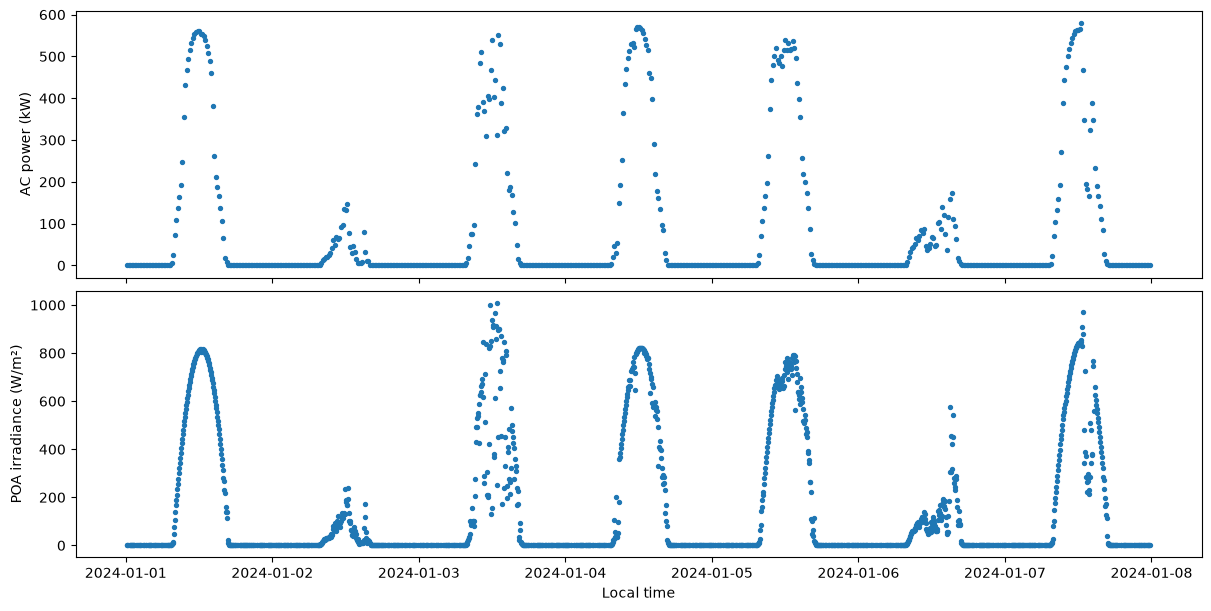

In [8]:
import matplotlib.pyplot as plt

# def plot_

start = "2024-01-01"
end = "2024-01-08"  # Exclusive

power_col = "meter_revenue_grade_ac_output_meter_149578"
irradiance_col = "poa_irradiance_o_149574"

meter_week = meter_data.loc[
    (meter_data["measured_on"] >= start)
    & (meter_data["measured_on"] < end)
]

irradiance_week = irradiance_data.loc[
    (irradiance_data["measured_on"] >= start)
    & (irradiance_data["measured_on"] < end)
]

fig, (ax_power, ax_irradiance) = plt.subplots(
    nrows=2, sharex=True, figsize=(12, 6), layout="constrained"
)

ax_power.scatter(meter_week["measured_on"], meter_week[power_col], s=8)
ax_power.set_ylabel("AC power (kW)")

ax_irradiance.scatter(
    irradiance_week["measured_on"], irradiance_week[irradiance_col], s=8
)
ax_irradiance.set_ylabel("POA irradiance (W/m²)")
ax_irradiance.set_xlabel("Local time")

plt.show()

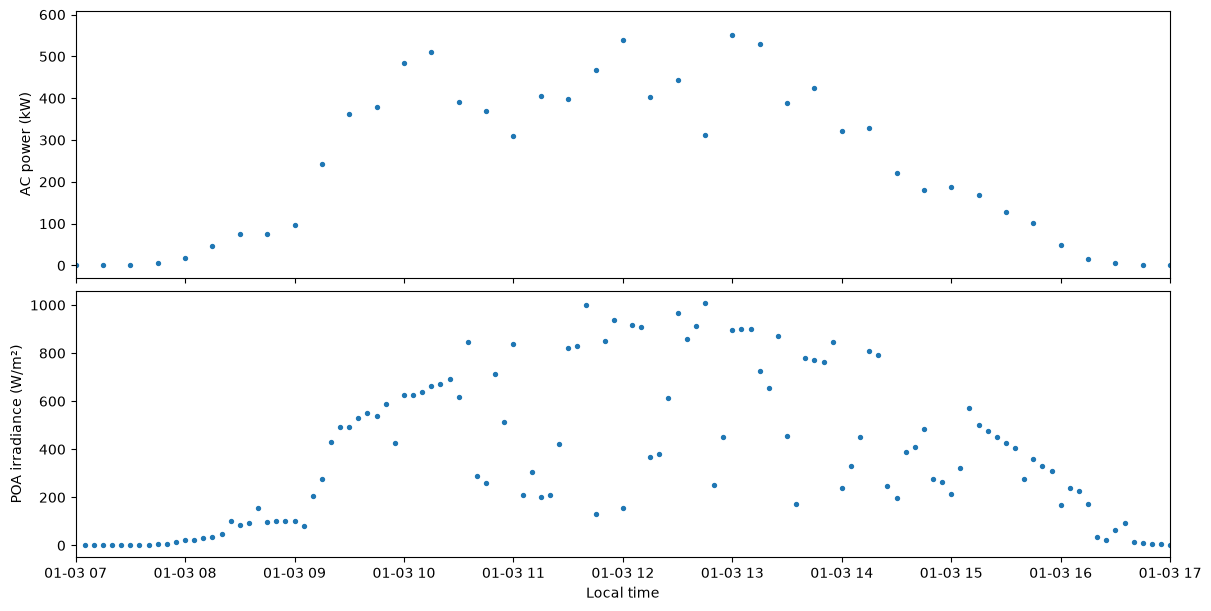

In [9]:
start = "2024-01-01"
end = "2024-01-08"  # Exclusive

power_col = "meter_revenue_grade_ac_output_meter_149578"
irradiance_col = "poa_irradiance_o_149574"

meter_week = meter_data.loc[
    (meter_data["measured_on"] >= start)
    & (meter_data["measured_on"] < end)
]

irradiance_week = irradiance_data.loc[
    (irradiance_data["measured_on"] >= start)
    & (irradiance_data["measured_on"] < end)
]

fig, (ax_power, ax_irradiance) = plt.subplots(
    nrows=2, sharex=True, figsize=(12, 6), layout="constrained"
)

ax_power.scatter(meter_week["measured_on"], meter_week[power_col], s=8)
ax_power.set_ylabel("AC power (kW)")

ax_irradiance.scatter(
    irradiance_week["measured_on"], irradiance_week[irradiance_col], s=8
)
ax_irradiance.set_ylabel("POA irradiance (W/m²)")
ax_irradiance.set_xlabel("Local time")

ax_irradiance.set_xlim(
    pd.Timestamp("2024-01-03 07:00"),
    pd.Timestamp("2024-01-03 17:00"),
)
plt.show()

### Review one low-output interval


In [10]:
start = pd.Timestamp("2024-01-03 12:45")
end = pd.Timestamp("2024-01-03 13:00")

poa_window = irradiance_week.loc[
    (irradiance_week["measured_on"] >= start)
    & (irradiance_week["measured_on"] < end),
    ["measured_on", irradiance_col],
]

print(poa_window)
print("Valid readings:", poa_window[irradiance_col].count())
print("Mean irradiance (W/m²):", poa_window[irradiance_col].mean())

            measured_on  poa_irradiance_o_149574
578 2024-01-03 12:45:00                   1008.9
579 2024-01-03 12:50:00                    251.8
580 2024-01-03 12:55:00                    451.3
Valid readings: 3
Mean irradiance (W/m²): 570.6666666666666


In [11]:
irradiance_15min = (
    irradiance_week.resample("15min", on="measured_on", label="left", closed="left")
    [irradiance_col]
    .agg(["mean", "count"])
    .rename(columns={"mean": "mean_poa", "count": "poa_readings"})
    .reset_index()
)

comparison = meter_week.merge(
    irradiance_15min,
    on="measured_on",
    how="left",
    validate="one_to_one",
)

comparison


,measured_on,meter_revenue_grade_ac_output_meter_149578,mean_poa,poa_readings
0,2024-01-01 00:15:00,0.0,0.0,2
1,2024-01-01 00:30:00,0.0,0.0,1
2,2024-01-01 00:45:00,0.0,0.0,3
3,2024-01-01 01:00:00,0.0,0.0,3
4,2024-01-01 01:15:00,0.0,0.0,3
...,...,...,...,...
666,2024-01-07 22:45:00,0.0,0.0,3
667,2024-01-07 23:00:00,0.0,0.0,1
668,2024-01-07 23:15:00,0.0,0.0,2
669,2024-01-07 23:30:00,0.0,0.0,3


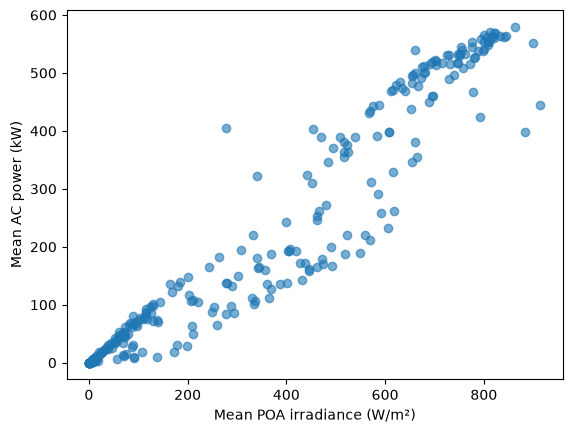

In [12]:
# Plot intervals with three valid irradiance readings and positive irradiance.
daylight = comparison.loc[
    (comparison["poa_readings"] == 3) & (comparison["mean_poa"] > 0)
]

plt.scatter(daylight["mean_poa"], daylight[power_col], alpha=0.6)
plt.xlabel("Mean POA irradiance (W/m²)")
plt.ylabel("Mean AC power (kW)")
plt.show()

In [13]:
candidates = comparison.loc[
    (comparison["mean_poa"] >= 750) & (comparison[power_col] < 450)
].sort_values(power_col)

candidates.head()

,measured_on,meter_revenue_grade_ac_output_meter_149578,mean_poa,poa_readings
237,2024-01-03 11:30:00,398.08,882.833333,3
246,2024-01-03 13:45:00,424.32,793.033333,3
241,2024-01-03 12:30:00,444.80,913.933333,3


In [14]:
target_time = pd.Timestamp("2024-01-03 11:30")
window_end = target_time + pd.Timedelta(minutes=15)
half_hour = pd.Timedelta(minutes=30)

raw_window = irradiance_week.loc[
    (irradiance_week["measured_on"] >= target_time)
    & (irradiance_week["measured_on"] < window_end),
    ["measured_on", irradiance_col],
].sort_values("measured_on")

neighbours = comparison.loc[
    comparison["measured_on"].between(
        target_time - half_hour, target_time + half_hour
    ),
    ["measured_on", power_col, "mean_poa", "poa_readings"],
].sort_values("measured_on")

display(raw_window)
display(neighbours)

,measured_on,poa_irradiance_o_149574
563,2024-01-03 11:30:00,820.1
564,2024-01-03 11:35:00,829.0
565,2024-01-03 11:40:00,999.4


,measured_on,meter_revenue_grade_ac_output_meter_149578,mean_poa,poa_readings
235,2024-01-03 11:00:00,309.76,451.766667,3
236,2024-01-03 11:15:00,405.76,277.600000,3
237,2024-01-03 11:30:00,398.08,882.833333,3
238,2024-01-03 11:45:00,468.48,640.066667,3
239,2024-01-03 12:00:00,539.52,660.466667,3


In [47]:
import matplotlib.dates as mdates

def plot_pv_day(aligned_data, day, start_time="10:30", end_time="13:00"):
    day = pd.Timestamp(day).date()
    start = pd.Timestamp(f"{day} {start_time}")
    end = pd.Timestamp(f"{day} {end_time}")
    interval = pd.Timedelta(minutes=15)

    window = aligned_data.loc[
        (aligned_data["measured_on"] >= start)
        & (aligned_data["measured_on"] < end)
    ].sort_values("measured_on")

    fig, (ax_irr, ax_power) = plt.subplots(
        2, 1, figsize=(11, 6), sharex=True, layout="constrained"
    )

    for ax, column, label, colour in [
        (ax_irr, "mean_poa", "Mean POA irradiance (W/m²)", "darkorange"),
        (ax_power, power_col, "Average AC power (kW)", "tab:blue"),
    ]:
        # Each horizontal segment covers the 15 minutes it represents.
        ax.hlines(
            y=window[column],
            xmin=window["measured_on"],
            xmax=window["measured_on"] + interval,
            color=colour,
            linewidth=2,
        )
        ax.set_ylabel(label)
        ax.set_ylim(
            min(0, comparison[column].min()),
            1.05 * comparison[column].max(),
        )
        ax.grid(alpha=0.25)

    ax_irr.set_title(f"{day:%d %B %Y} · PVDAQ System 2107")
    ax_power.set_xlabel("Site time")
    ax_power.set_xlim(start, end)
    ax_power.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    plt.show()

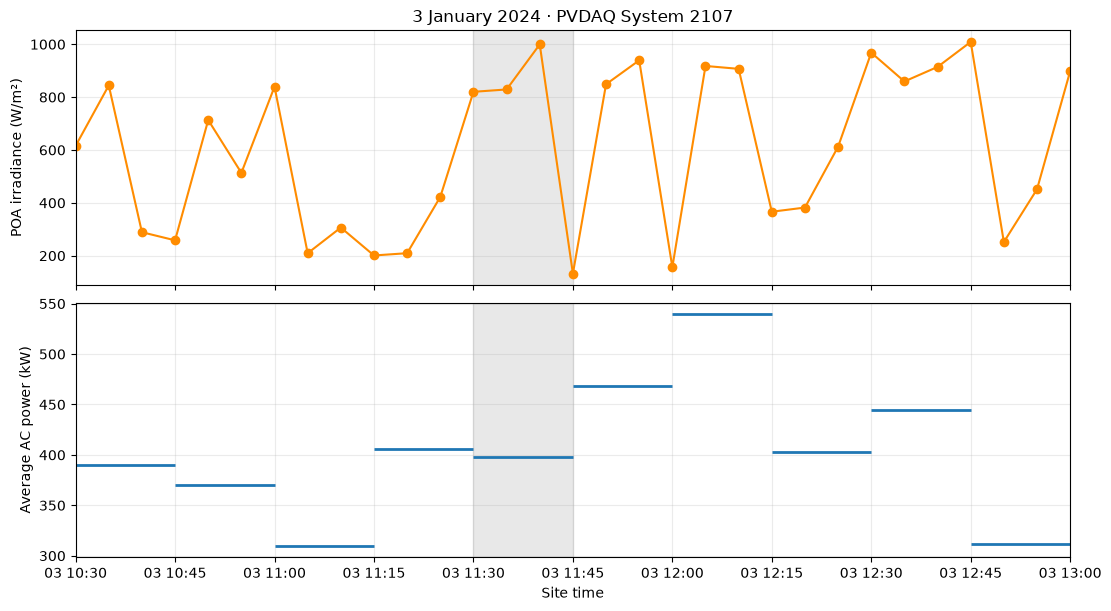

In [15]:
start = pd.Timestamp("2024-01-03 10:30")
stop = pd.Timestamp("2024-01-03 13:00")
target = pd.Timestamp("2024-01-03 11:30")
interval = pd.Timedelta(minutes=15)

irr_plot = irradiance_week.loc[
    irradiance_week["measured_on"].between(start, stop),
    ["measured_on", irradiance_col],
].sort_values("measured_on")

power_plot = meter_week.loc[
    (meter_week["measured_on"] >= start) & (meter_week["measured_on"] < stop),
    ["measured_on", power_col],
].sort_values("measured_on")

fig, (ax_irr, ax_power) = plt.subplots(
    2, 1, figsize=(11, 6), sharex=True, layout="constrained"
)

ax_irr.plot(
    irr_plot["measured_on"], irr_plot[irradiance_col],
    marker="o", color="darkorange",
)
ax_irr.set_ylabel("POA irradiance (W/m²)")
ax_irr.set_title("3 January 2024 · PVDAQ System 2107")

# Draw each average across the 15 minutes it represents.
ax_power.hlines(
    y=power_plot[power_col],
    xmin=power_plot["measured_on"],
    xmax=power_plot["measured_on"] + interval,
    color="tab:blue",
    linewidth=2,
)
ax_power.set_ylabel("Average AC power (kW)")
ax_power.set_xlabel("Site time")
ax_power.set_xlim(start, stop)

for ax in (ax_irr, ax_power):
    ax.axvspan(target, target + interval, color="grey", alpha=0.18)
    ax.grid(alpha=0.25)

plt.show()

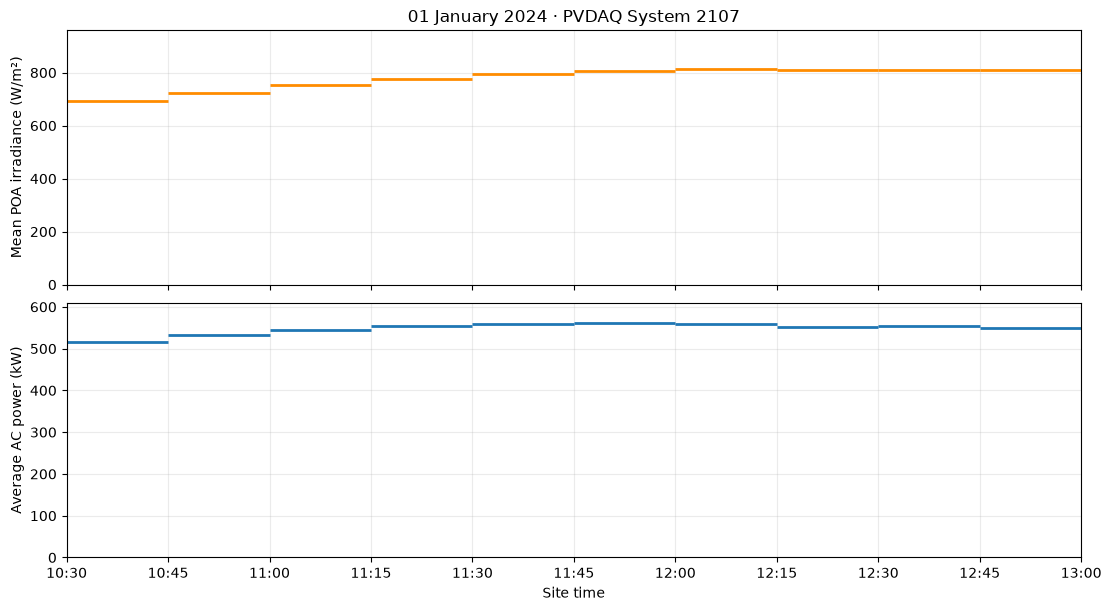

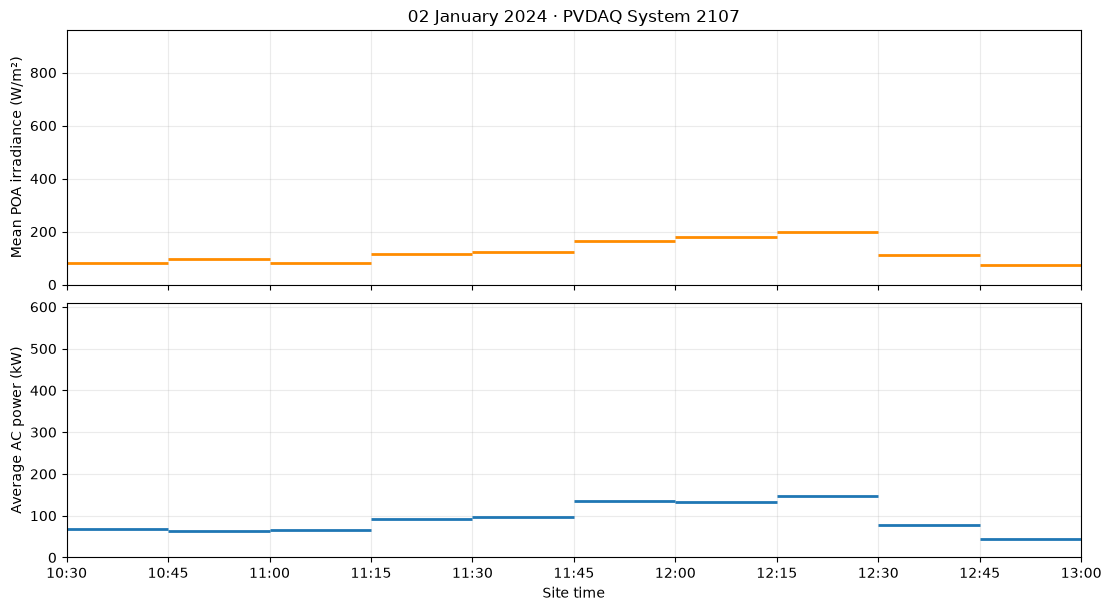

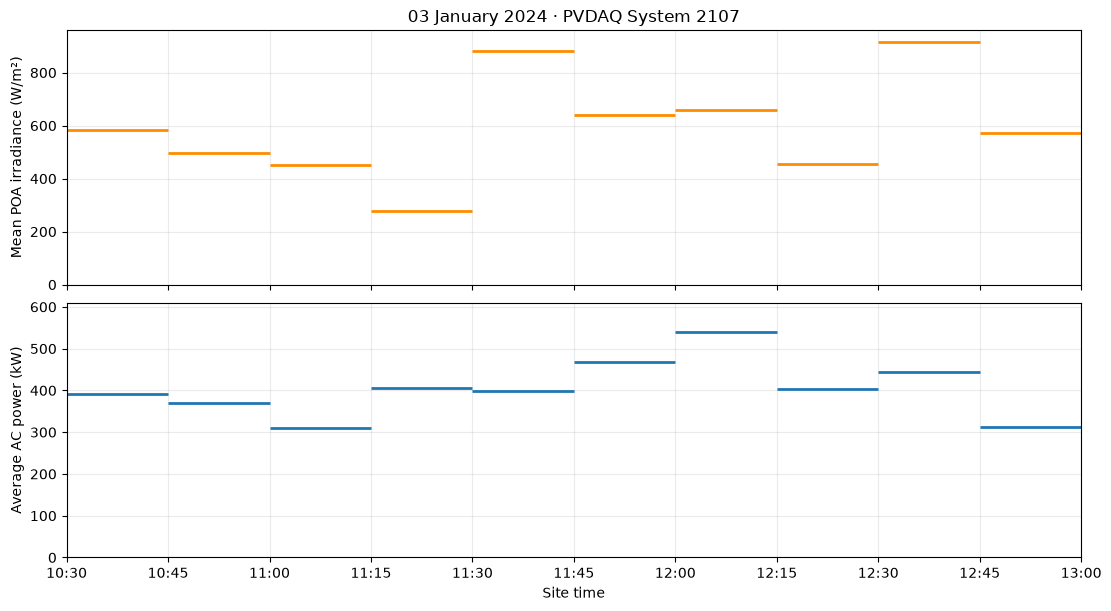

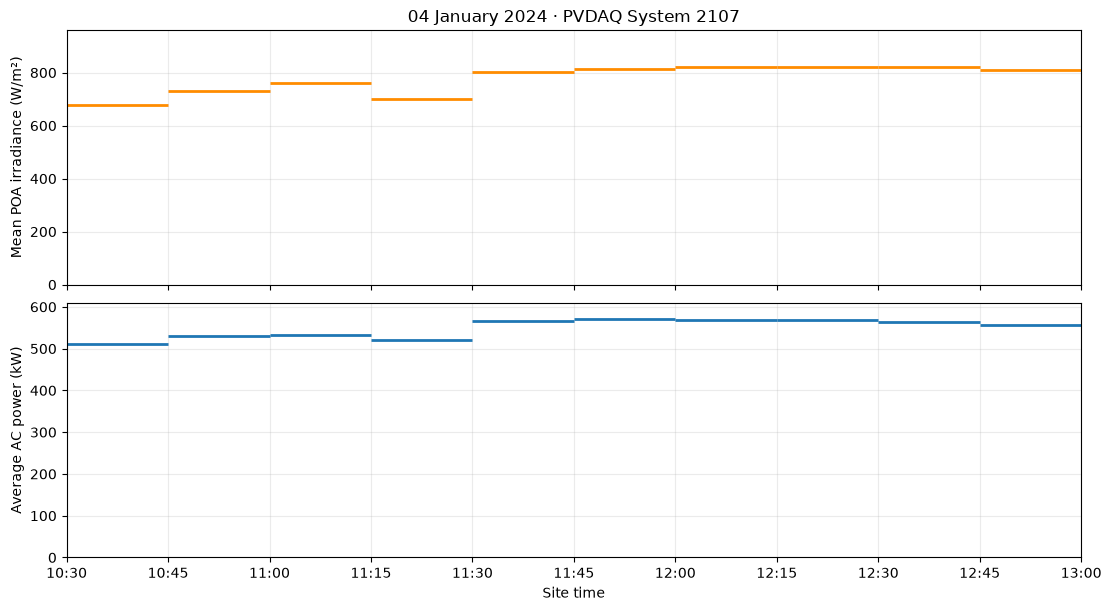

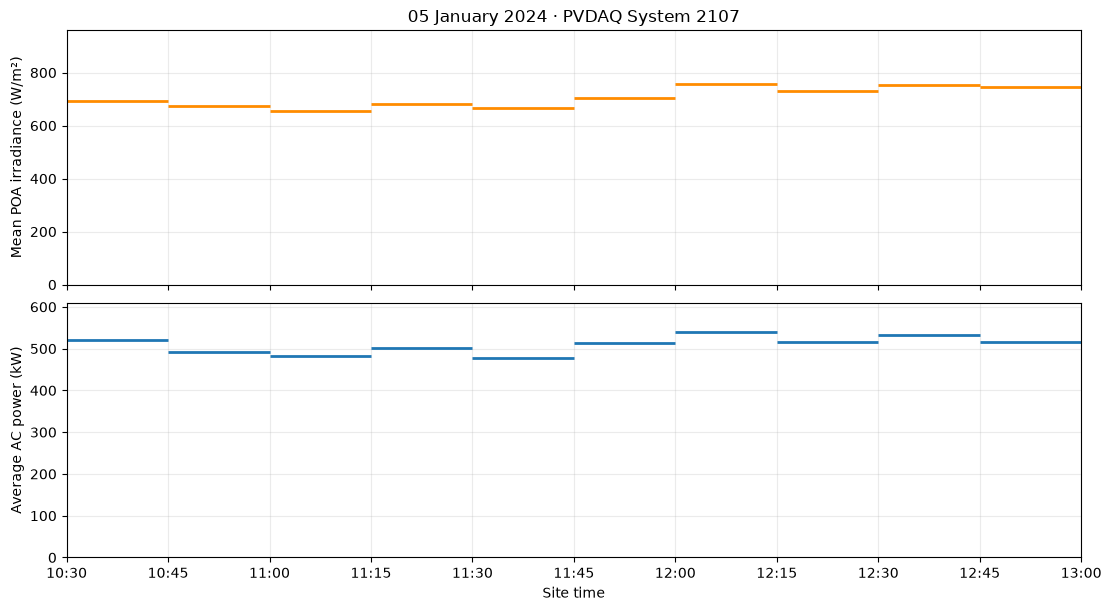

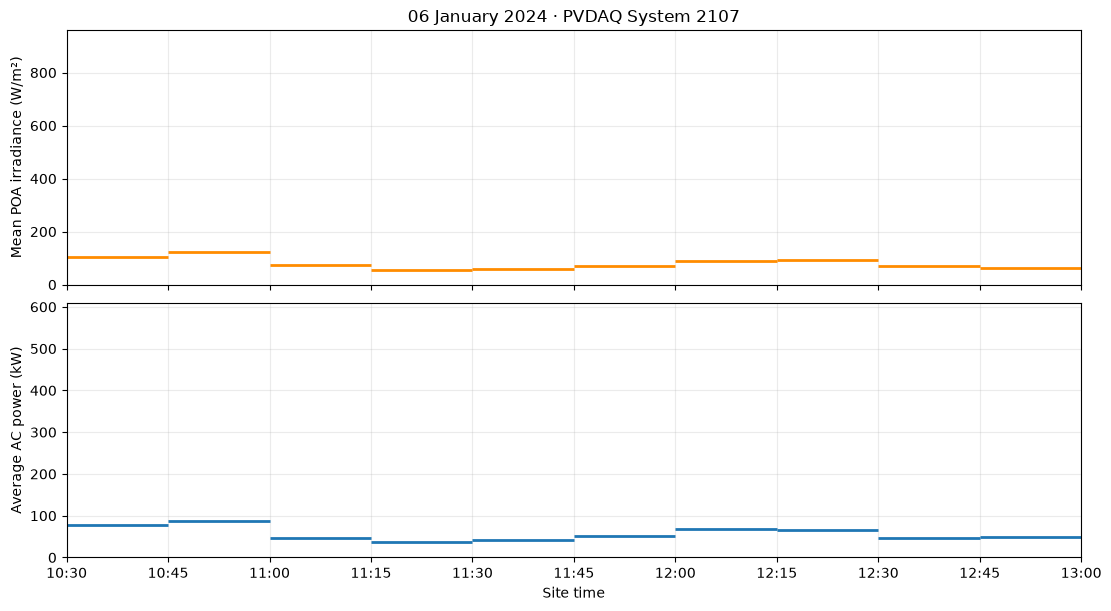

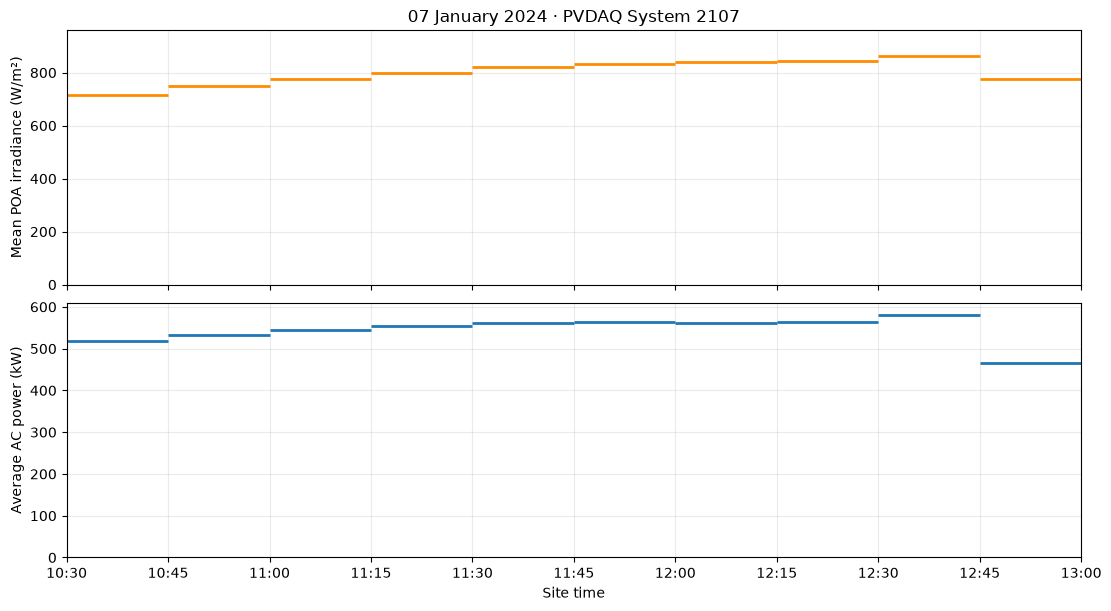

In [22]:
# plot_pv_day("2024-01-03", "10:30", "13:00")

for day in pd.date_range("2024-01-01", "2024-01-07"):
    plot_pv_day(day, "10:30", "13:00")

In [31]:
target_irradiance = 882.83

similar_intervals = comparison.loc[
    comparison["mean_poa"].between(
        target_irradiance - 25, target_irradiance + 25
    )
    & comparison["poa_readings"].eq(3)
    & comparison["measured_on"].dt.normalize().ne(pd.Timestamp("2024-01-03"))
    & comparison[power_col].notna(),
    ["measured_on", "mean_poa", power_col],
]

similar_intervals

,measured_on,mean_poa,meter_revenue_grade_ac_output_meter_149578
625,2024-01-07 12:30:00,863.866667,579.84


In [43]:
irradiance_15min_whole = (
    irradiance_data.resample("15min", on="measured_on", label="left", closed="left")
    [irradiance_col]
    .agg(["mean", "count"])
    .rename(columns={"mean": "mean_poa", "count": "poa_readings"})
    .reset_index()
)


aligned = meter_data.merge(
    irradiance_15min_whole,
    on="measured_on",
    how="left",
    validate="one_to_one",
)


target_irradiance = 882.83

similar_intervals = aligned.loc[
    aligned["mean_poa"].between(
        target_irradiance - 25, target_irradiance + 25
    )
    & aligned["poa_readings"].eq(3)
    & aligned["measured_on"].dt.normalize().ge(pd.Timestamp("2024-01-07"))
    # & aligned["measured_on"].dt.normalize().ne(pd.Timestamp("2024-01-07"))
    & aligned[power_col].notna(),
    ["measured_on", "mean_poa", power_col],
]

print("Matching intervals:", len(similar_intervals))
print("Distinct days:", similar_intervals["measured_on"].dt.normalize().nunique())
print(similar_intervals[power_col].describe())

Matching intervals: 790
Distinct days: 245
count    790.000000
mean     583.384304
std       56.497797
min      187.520000
25%      543.360000
50%      576.960000
75%      624.480000
max      704.640000
Name: meter_revenue_grade_ac_output_meter_149578, dtype: float64


In [44]:
january_matches = similar_intervals.loc[
    similar_intervals["measured_on"].dt.month.eq(1)
]

print("Distinct January days:", january_matches["measured_on"].dt.normalize().nunique())
display(january_matches[power_col].describe())

print("Full-period intervals at or below 398.08 kW:",
      similar_intervals[power_col].le(398.08).sum())

Distinct January days: 6


count     10.000000
mean     573.376000
std      138.070497
min      187.520000
25%      584.960000
50%      606.400000
75%      640.000000
max      648.320000
Name: meter_revenue_grade_ac_output_meter_149578, dtype: float64

Full-period intervals at or below 398.08 kW: 1


In [45]:
display(
    similar_intervals.loc[similar_intervals[power_col].le(398.08)]
)

,measured_on,mean_poa,meter_revenue_grade_ac_output_meter_149578
1394,2024-01-15 12:45:00,859.166667,187.52


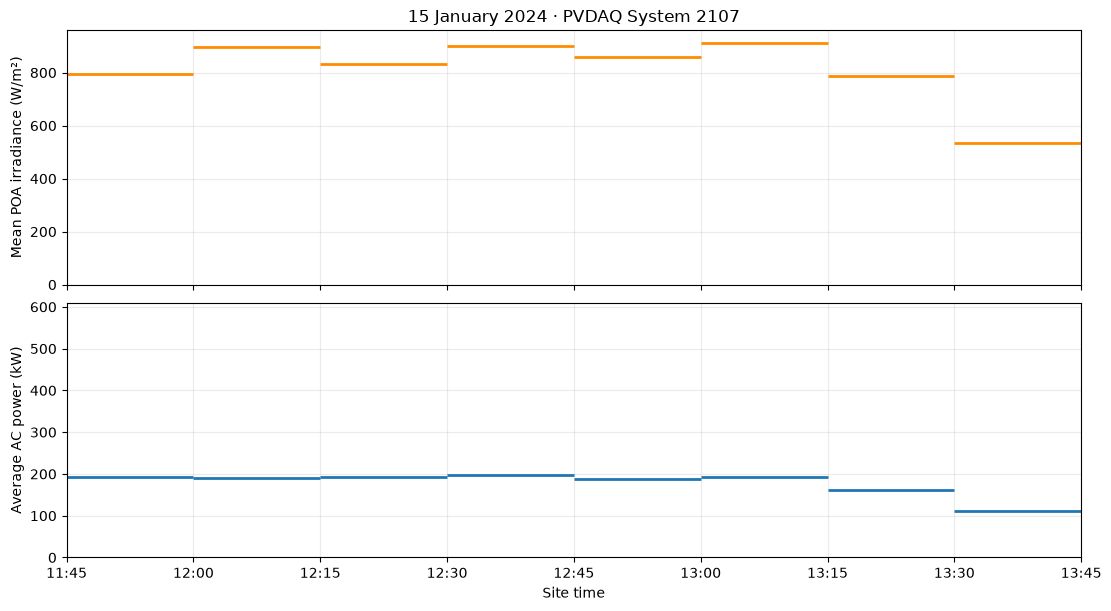

In [49]:
plot_pv_day(aligned, "2024-01-15", "11:45", "13:45")

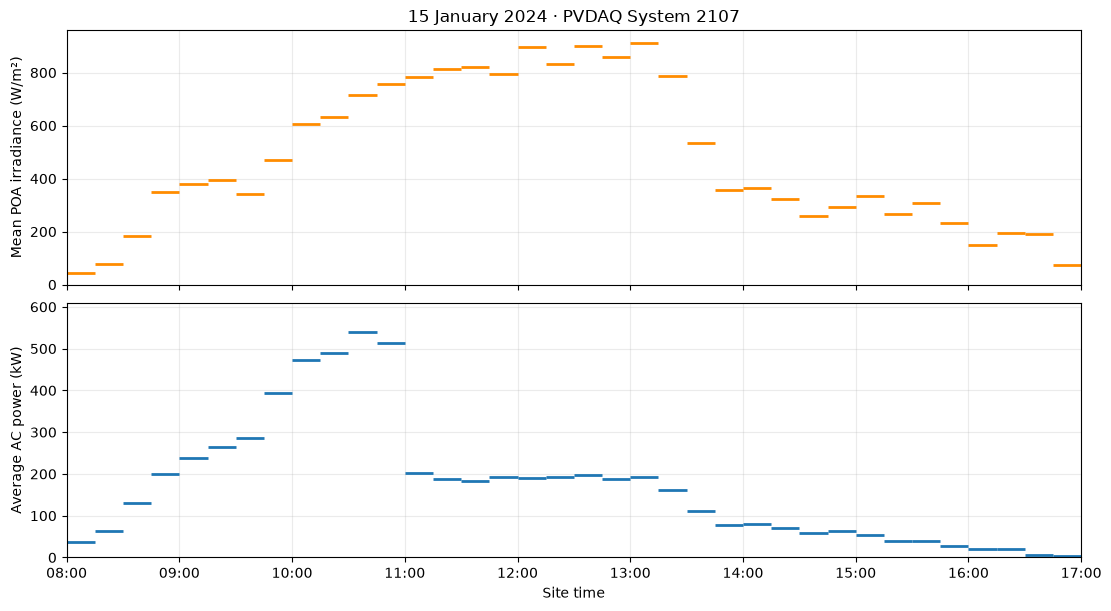

In [50]:
plot_pv_day(aligned, "2024-01-15", "08:00", "17:00")

In [51]:
start = pd.Timestamp("2024-01-15 11:00")
end = pd.Timestamp("2024-01-15 13:15")
timestamps = aligned["measured_on"]

# Use 8–31 January as the reference period, excluding the event day.
reference = aligned.loc[
    timestamps.ge("2024-01-08")
    & timestamps.lt("2024-02-01")
    & timestamps.dt.normalize().ne(start.normalize())
    & aligned["poa_readings"].eq(3)
    & aligned[power_col].notna()
]

# Keep all nine expected timestamps so missing intervals remain visible.
event_times = pd.date_range(start, end, freq="15min", inclusive="left")
event = (
    aligned.set_index("measured_on")
    .reindex(event_times)[["mean_poa", "poa_readings", power_col]]
    .rename_axis("measured_on")
    .rename(columns={power_col: "actual_kw"})
)

event["expected_kw"] = float("nan")
event["reference_days"] = 0

for timestamp, row in event.iterrows():
    if row["poa_readings"] != 3 or pd.isna(row["actual_kw"]):
        continue

    irradiance = row["mean_poa"]
    matches = reference.loc[
        reference["mean_poa"].between(irradiance - 25, irradiance + 25)
    ]

    event.loc[timestamp, "expected_kw"] = matches[power_col].median()
    event.loc[timestamp, "reference_days"] = (
        matches["measured_on"].dt.normalize().nunique()
    )

event["shortfall_kwh"] = (event["expected_kw"] - event["actual_kw"]) * 0.25

display(event.round(2))

covered = event["shortfall_kwh"].count()
print(f"Intervals estimated: {covered}/{len(event)}")

if covered:
    total = event["shortfall_kwh"].sum()
    print(f"Estimated net energy shortfall over covered intervals: {total:.1f} kWh")

,mean_poa,poa_readings,actual_kw,expected_kw,reference_days,shortfall_kwh
measured_on,,,,,,
2024-01-15 11:00:00,784.57,3.0,202.24,571.20,8,92.24
2024-01-15 11:15:00,814.10,3.0,188.80,586.56,10,99.44
2024-01-15 11:30:00,822.67,3.0,183.68,590.40,10,101.68
2024-01-15 11:45:00,794.17,3.0,192.00,579.20,9,96.80
2024-01-15 12:00:00,895.10,2.0,191.36,NaN,0,NaN
2024-01-15 12:15:00,830.95,2.0,192.00,NaN,0,NaN
2024-01-15 12:30:00,900.35,2.0,197.76,NaN,0,NaN
2024-01-15 12:45:00,859.17,3.0,187.52,606.72,9,104.80
2024-01-15 13:00:00,913.27,3.0,193.28,NaN,0,NaN


Intervals estimated: 5/9
Estimated net energy shortfall over covered intervals: 495.0 kWh


On 15 January, estimated AC energy output was 495 kWh below the January irradiance-matched baseline across five of nine 15-minute intervals assessed between 11:00 and 13:15. The estimate covers 75 minutes of the 135-minute window.